In [6]:
"""import sys
!{sys.executable} -m pip install --upgrade pip
!{sys.executable} -m pip install opencv-python matplotlib numpy
"""

'import sys\n!{sys.executable} -m pip install --upgrade pip\n!{sys.executable} -m pip install opencv-python matplotlib numpy\n'

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
print("✅ 所有必要的函式庫已成功導入！")

✅ 所有必要的函式庫已成功導入！


In [9]:
def show_preview(img, pts_pct):
    """根據 0~100 的百分比座標計算透視變換並在 Notebook 內繪製雙圖預覽"""
    img_h, img_w = img.shape[:2]
    
    # 將 0~100 的數值除以 100.0，換算為實際像素座標 (左上 -> 右上 -> 右下 -> 左下)
    src_pts = np.float32([
        [pts_pct[0][0] / 100.0 * img_w, pts_pct[0][1] / 100.0 * img_h], # 左上
        [pts_pct[1][0] / 100.0 * img_w, pts_pct[1][1] / 100.0 * img_h], # 右上
        [pts_pct[2][0] / 100.0 * img_w, pts_pct[2][1] / 100.0 * img_h], # 右下
        [pts_pct[3][0] / 100.0 * img_w, pts_pct[3][1] / 100.0 * img_h]  # 左下
    ])
    
    # 計算變形後目標影像的最大寬高
    (tl, tr, br, bl) = src_pts
    width_top = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
    width_bottom = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
    max_width = max(int(width_top), int(width_bottom), 1)

    height_left = np.sqrt(((tl[0] - bl[0]) ** 2) + ((tl[1] - bl[1]) ** 2))
    height_right = np.sqrt(((tr[0] - br[0]) ** 2) + ((tr[1] - br[1]) ** 2))
    max_height = max(int(height_left), int(height_right), 1)

    dst_pts = np.float32([[0,0],
        [max_width - 1, 0],
        [max_width - 1, max_height - 1],
        [0, max_height - 1]
    ])

    # 執行透視變形
    M = cv2.getPerspectiveTransform(src_pts, dst_pts)
    warped = cv2.warpPerspective(img, M, (max_width, max_height))

    # 轉換為 RGB 格式供 Matplotlib 在網頁渲染
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    warped_rgb = cv2.cvtColor(warped, cv2.COLOR_BGR2RGB)

    # 畫出對比預覽圖
    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)
    plt.title("Original Configuration")
    plt.imshow(img_rgb)
    
    # 在原圖上標註目前的四個點位置與 0~100 的數值
    labels = ['1.TL', '2.TR', '3.BR', '4.BL']
    colors = ['red', 'green', 'blue', 'orange']
    for i, pt in enumerate(src_pts):
        plt.scatter(pt[0], pt[1], color=colors[i], s=50, zorder=5)
        plt.text(pt[0]+15, pt[1]+15, f"{labels[i]}\n({pts_pct[i][0]},{pts_pct[i][1]})", 
                 color=colors[i], fontsize=9, weight='bold')
        
    polygon = np.vstack([src_pts, src_pts[0]])
    plt.plot(polygon[:, 0], polygon[:, 1], color='cyan', linestyle='--', linewidth=2)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("Warped Result")
    plt.imshow(warped_rgb)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    return warped

print("✅ 預覽函數定義完成！")

✅ 預覽函數定義完成！


📸 影像讀取成功！請輸入初始四角百分比 (範圍 0 ~ 100，支援小數點)：

--- 正在生成初始預覽圖... ---


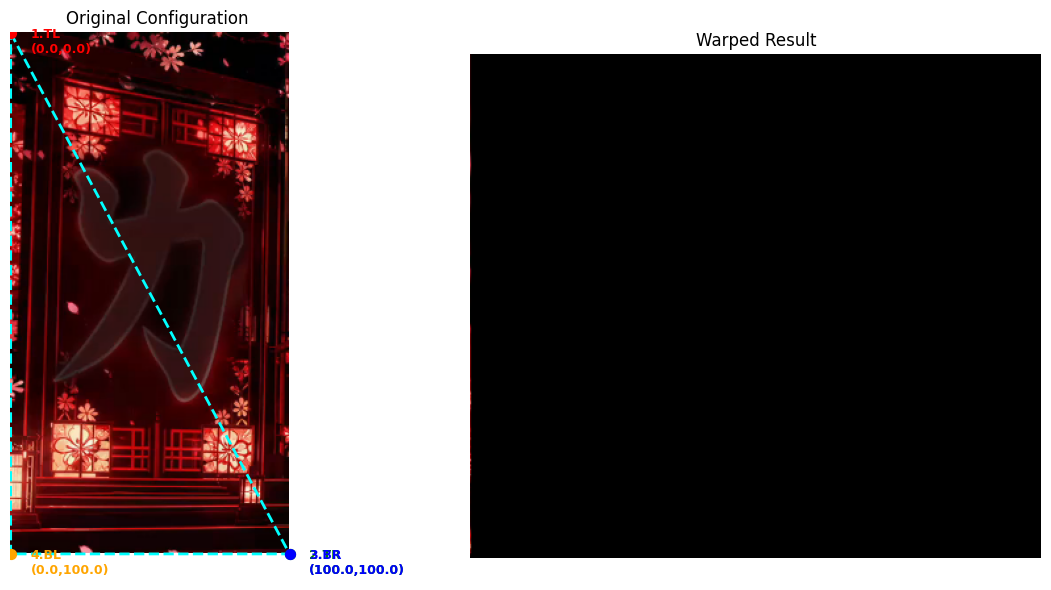

In [11]:
# 請確保此路徑與檔名完全沒有中文字元
image_path = 'D:/Users/User/Downloads/screenshot 2026-10-27 230009.png' 
global_img = cv2.imread(image_path)

if global_img is None:
    print(f"❌ 錯誤：找不到影像，請檢查純英文路徑是否正確：'{image_path}'")
else:
    print("📸 影像讀取成功！請輸入初始四角百分比 (範圍 0 ~ 100，支援小數點)：")
    
    # 初始化全域座標陣列
    current_pts = [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
    
    current_pts[0][0] = float(input("1. 左上 X (預設填 10): ") or 10.0)
    current_pts[0][1] = float(input("1. 左上 Y (預設填 10): ") or 10.0)
    
    current_pts[1][0] = float(input("2. 右上 X (預設填 90): ") or 90.0)
    current_pts[1][1] = float(input("2. 右上 Y (預設填 10): ") or 10.0)
    
    current_pts[2][0] = float(input("3. 右下 X (預設填 90): ") or 90.0)
    current_pts[2][1] = float(input("3. 右下 Y (預設填 90): ") or 90.0)
    
    current_pts[3][0] = float(input("4. 左下 X (預設填 10): ") or 10.0)
    current_pts[3][1] = float(input("4. 左下 Y (預設填 90): ") or 90.0)

    print("\n--- 正在生成初始預覽圖... ---")
    last_warped = show_preview(global_img, current_pts)



你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右上 為 X: 100.0, Y: 100.0

--- 已更新 右上 座標，重新生成預覽中... ---


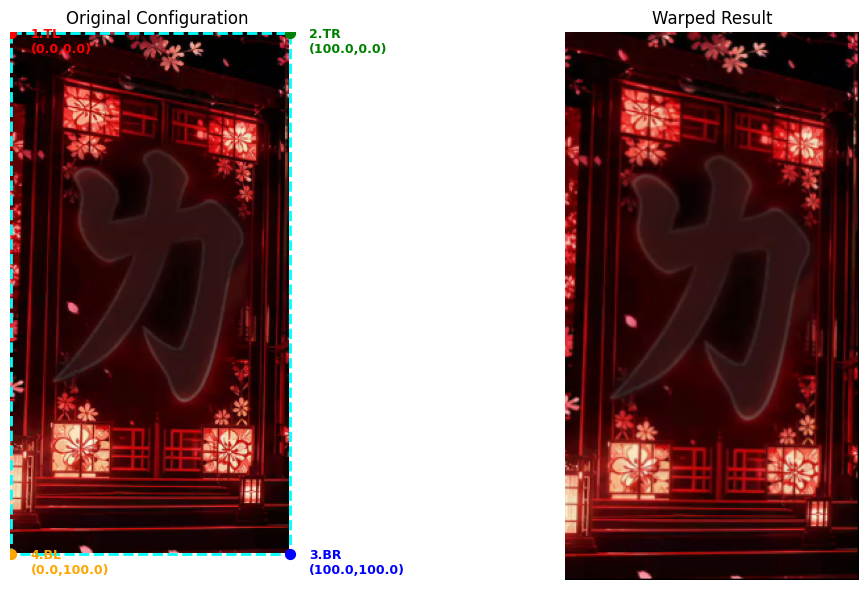


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右上 為 X: 100.0, Y: 0.0

--- 已更新 右上 座標，重新生成預覽中... ---


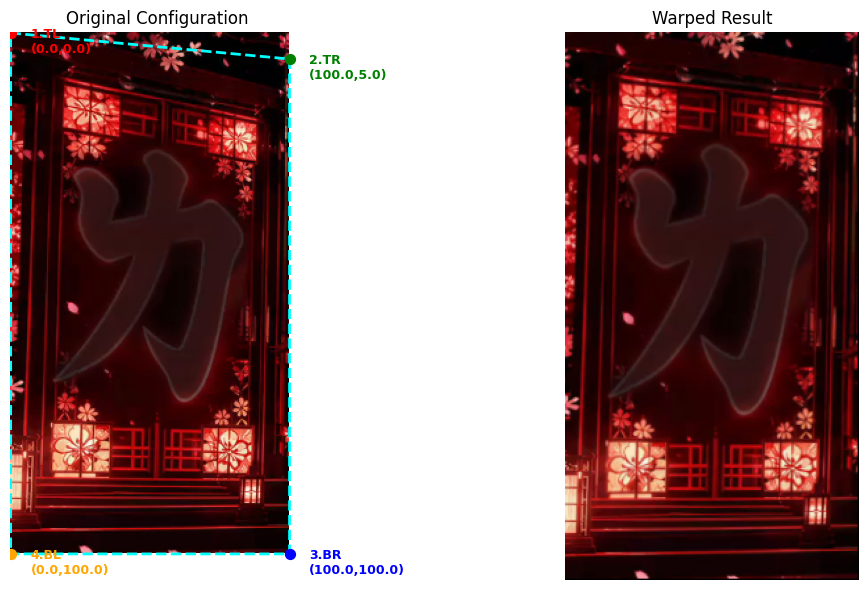


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 左上 為 X: 0.0, Y: 0.0

--- 已更新 左上 座標，重新生成預覽中... ---


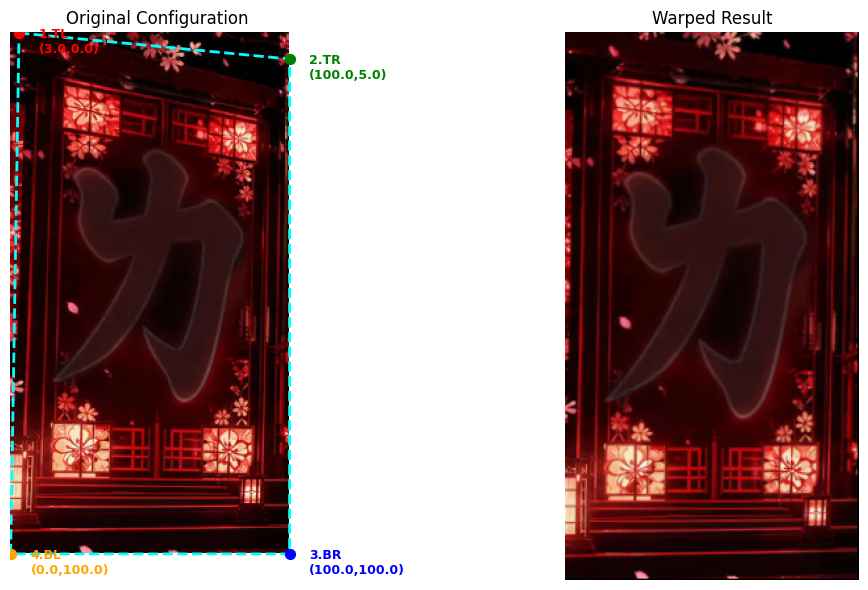


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右下 為 X: 100.0, Y: 100.0

--- 已更新 右下 座標，重新生成預覽中... ---


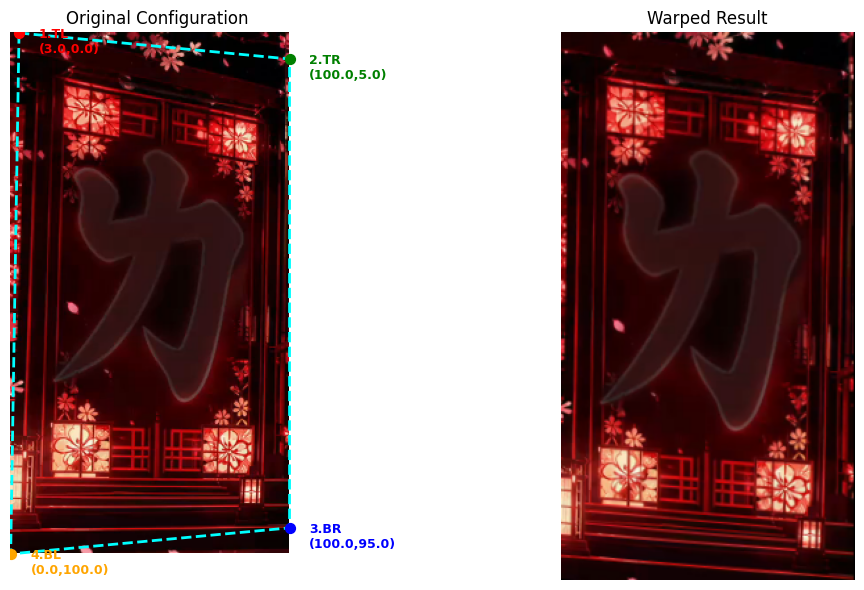


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 左下 為 X: 0.0, Y: 100.0

--- 已更新 左下 座標，重新生成預覽中... ---


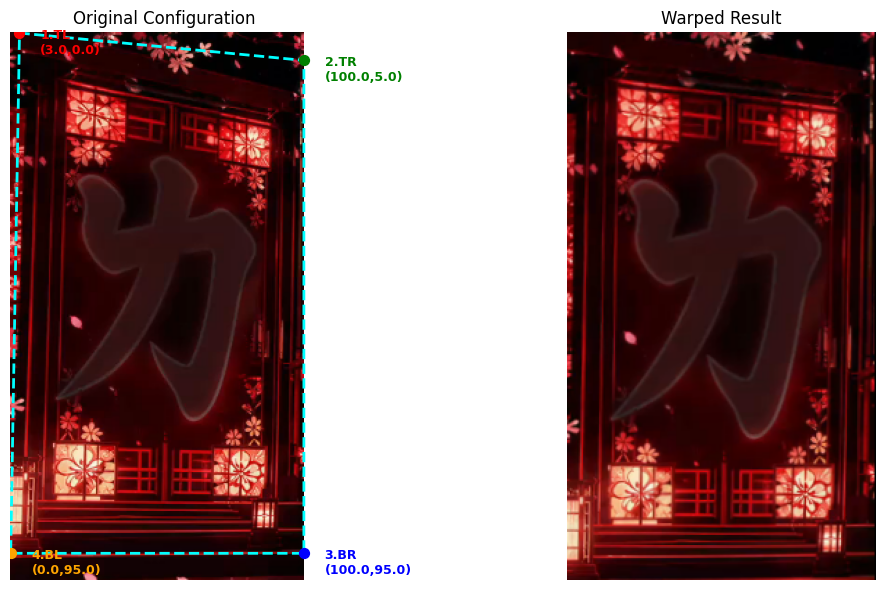


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 左下 為 X: 0.0, Y: 95.0

--- 已更新 左下 座標，重新生成預覽中... ---


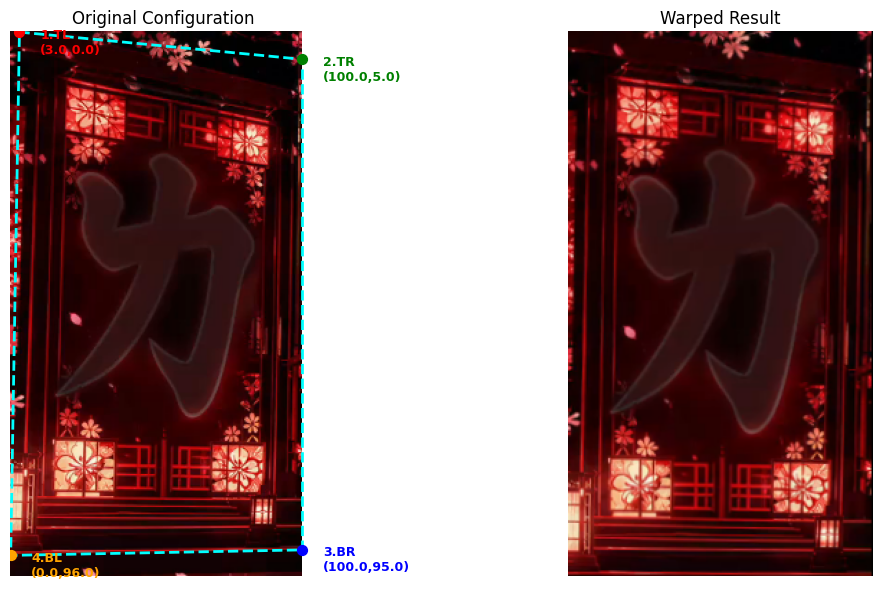


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右上 為 X: 100.0, Y: 5.0

--- 已更新 右上 座標，重新生成預覽中... ---


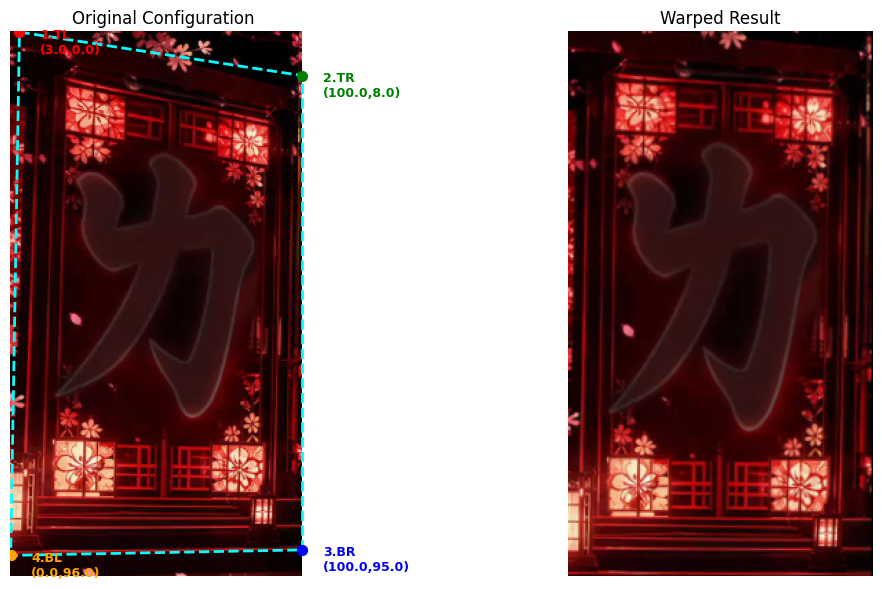


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 左上 為 X: 3.0, Y: 0.0

--- 已更新 左上 座標，重新生成預覽中... ---


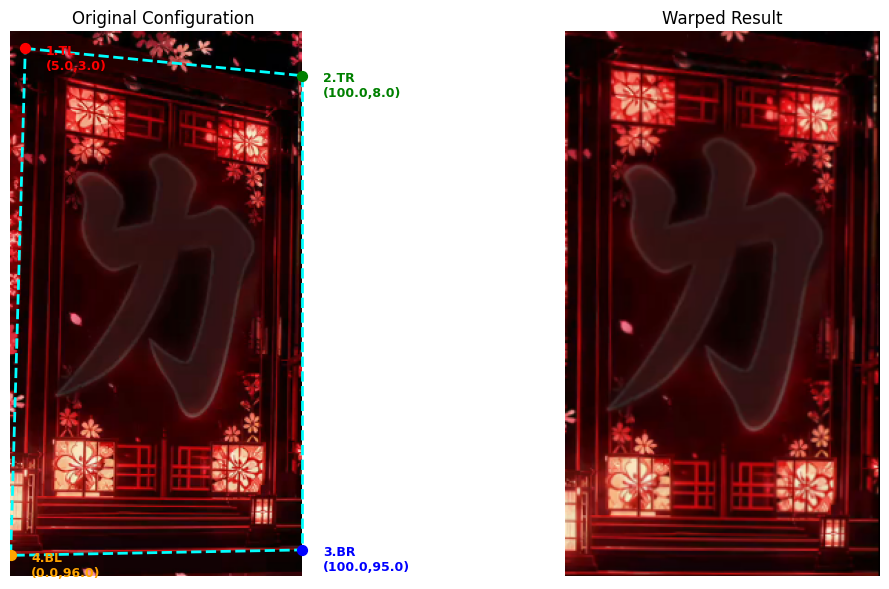


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右上 為 X: 100.0, Y: 8.0

--- 已更新 右上 座標，重新生成預覽中... ---


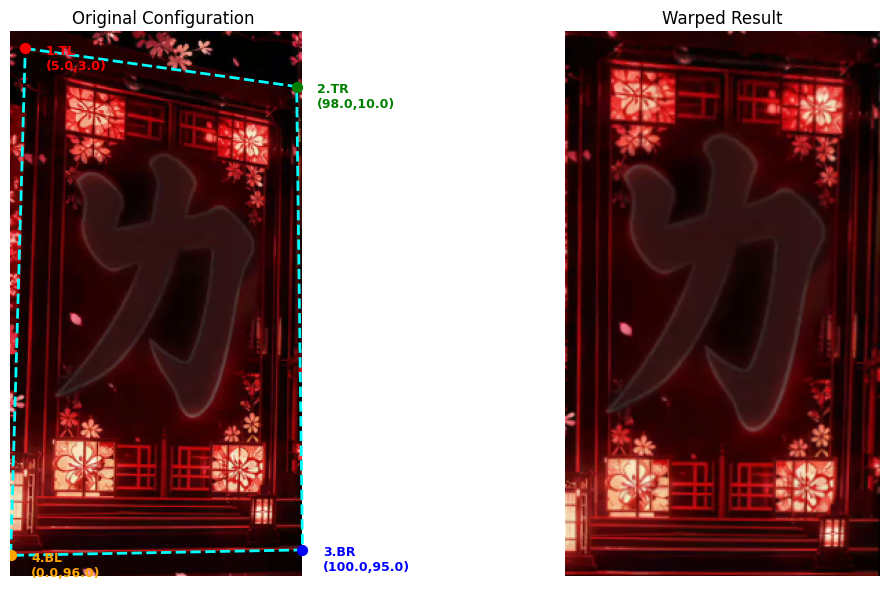


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右上 為 X: 98.0, Y: 10.0

--- 已更新 右上 座標，重新生成預覽中... ---


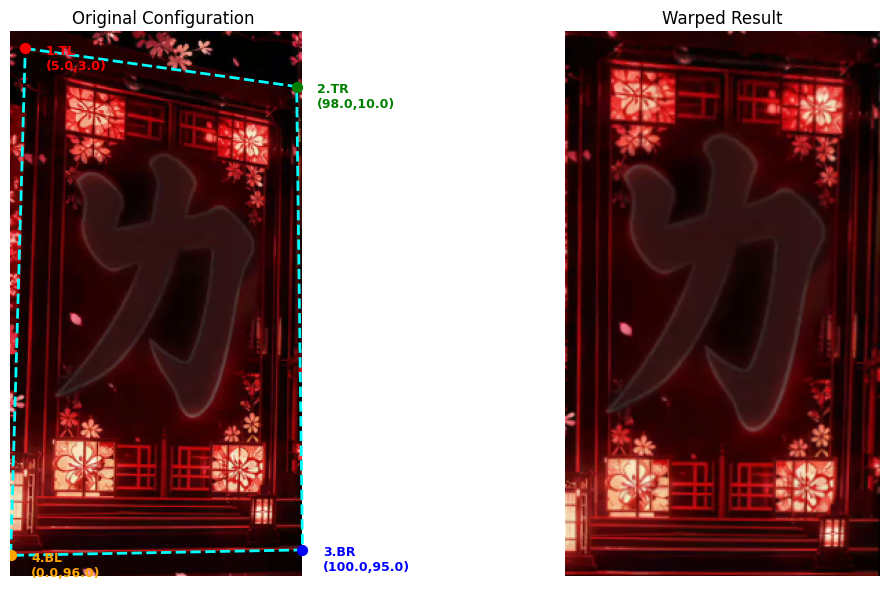


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右下 為 X: 100.0, Y: 95.0

--- 已更新 右下 座標，重新生成預覽中... ---


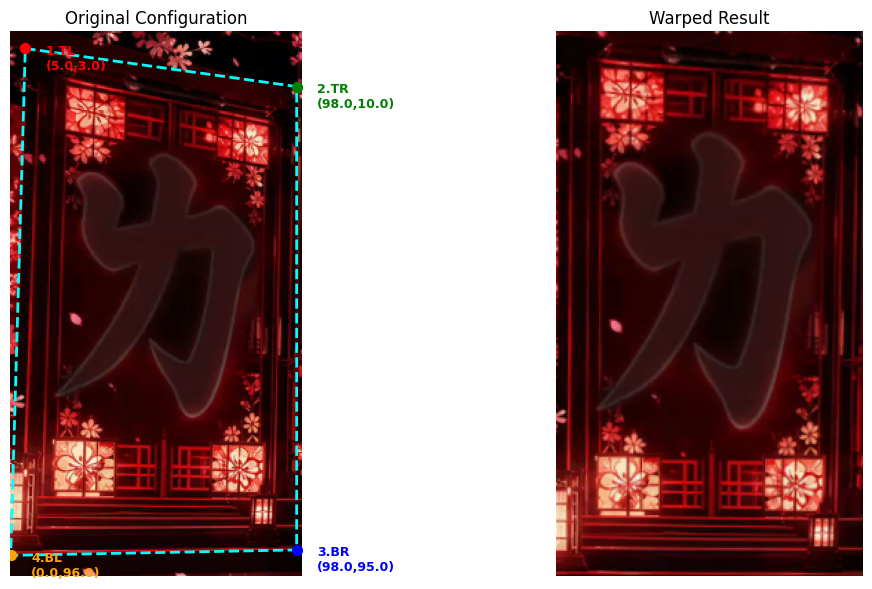


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右下 為 X: 98.0, Y: 95.0

--- 已更新 右下 座標，重新生成預覽中... ---


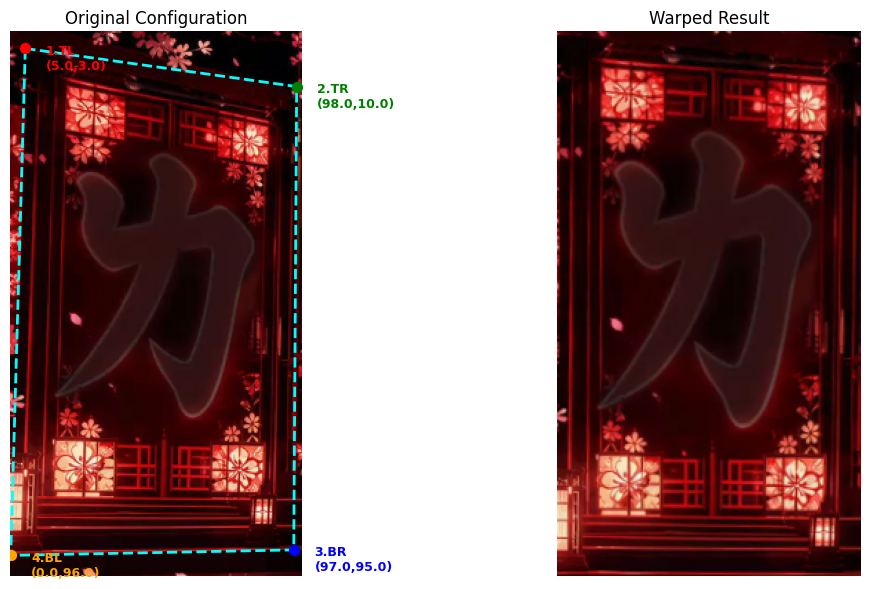


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右下 為 X: 97.0, Y: 95.0

--- 已更新 右下 座標，重新生成預覽中... ---


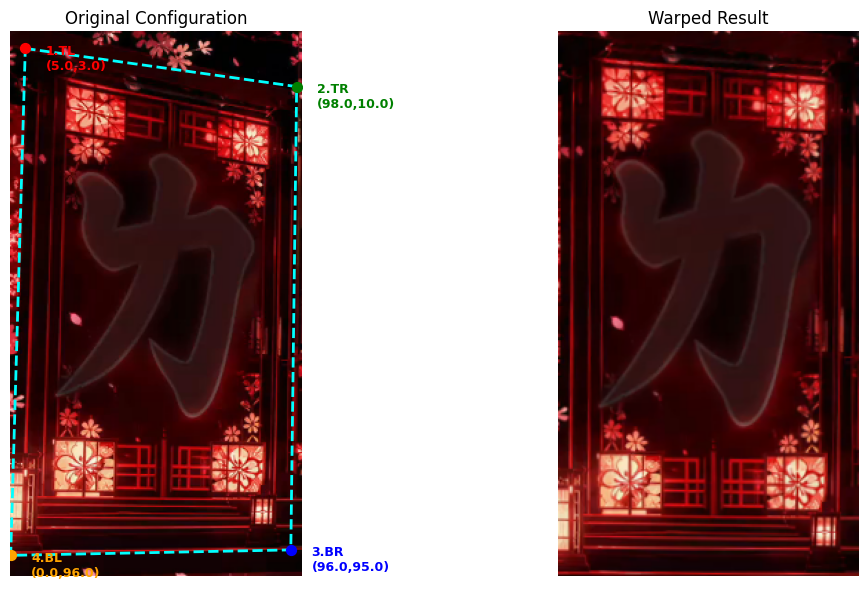


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右下 為 X: 96.0, Y: 95.0

--- 已更新 右下 座標，重新生成預覽中... ---


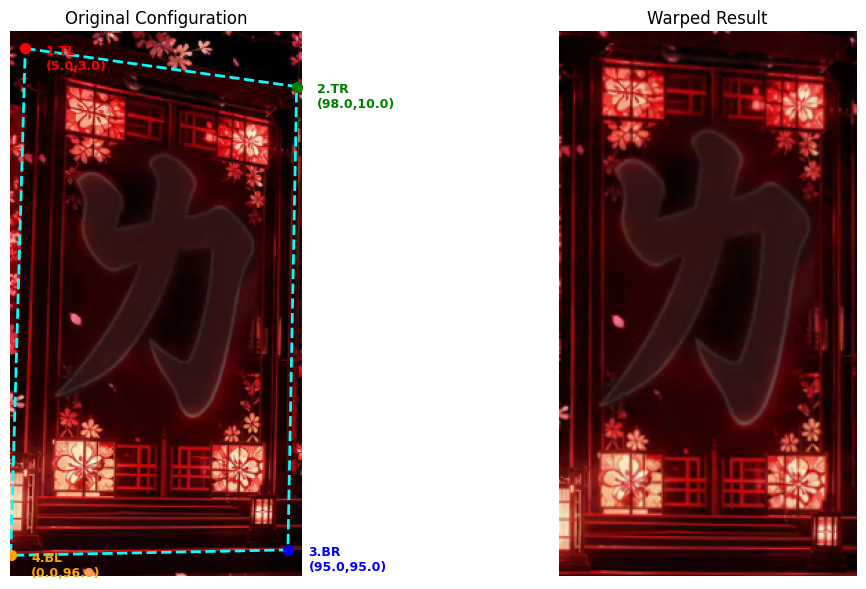


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

[微調模式] 目前 右上 為 X: 98.0, Y: 10.0

--- 已更新 右上 座標，重新生成預覽中... ---


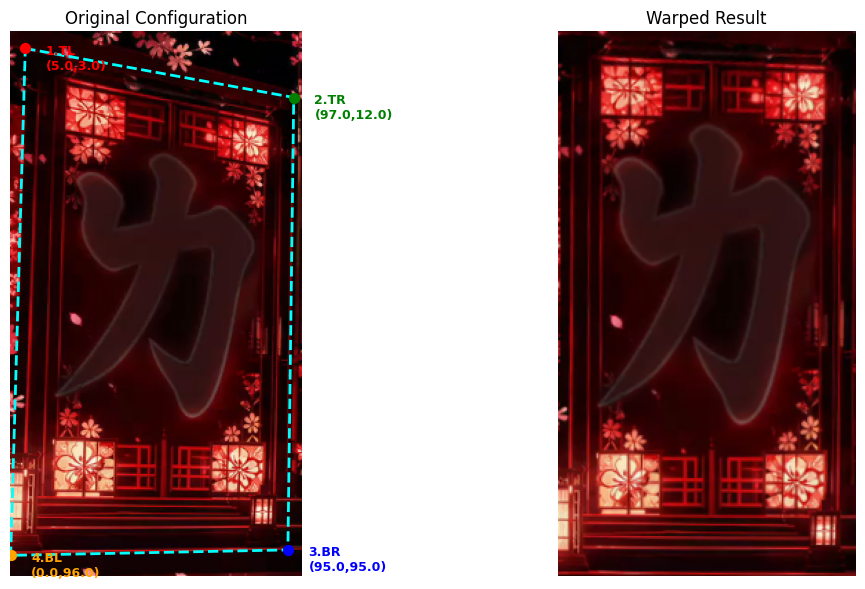


你想要更改哪個數字？
1: 左上 (TL)  |  2: 右上 (TR)
3: 右下 (BR)  |  4: 左下 (BL)
5: 無 (滿意結果，存檔並結束)

🎉 成功！最終變形結果已儲存為 'warped_result.jpg'。


In [12]:
while True:
    print("\n========================================")
    print("你想要更改哪個數字？")
    print("1: 左上 (TL)  |  2: 右上 (TR)")
    print("3: 右下 (BR)  |  4: 左下 (BL)")
    print("5: 無 (滿意結果，存檔並結束)")
    print("========================================")
    
    choice = input("請輸入選項 (1-5): ").strip()
    
    if choice == '5':
        cv2.imwrite('warped_result.jpg', last_warped)
        print("\n🎉 成功！最終變形結果已儲存為 'warped_result.jpg'。")
        break
        
    elif choice in ['1', '2', '3', '4']:
        idx = int(choice) - 1
        pt_names = ["左上", "右上", "右下", "左下"]
        
        print(f"\n[微調模式] 目前 {pt_names[idx]} 為 X: {current_pts[idx][0]}, Y: {current_pts[idx][1]}")
        
        try:
            new_x = input(f"請輸入新 {pt_names[idx]} X (直接按 Enter 代表不改): ")
            new_y = input(f"請輸入新 {pt_names[idx]} Y (直接按 Enter 代表不改): ")
            
            if new_x: current_pts[idx][0] = float(new_x)
            if new_y: current_pts[idx][1] = float(new_y)
            
            # 限制使用者輸入的範圍在 0 ~ 100 之間
            if not (0.0 <= current_pts[idx][0] <= 100.0) or not (0.0 <= current_pts[idx][1] <= 100.0):
                print("⚠️ 警告：輸入的數字超出 0~100 範圍，請重新輸入！")
                continue
            
            print(f"\n--- 已更新 {pt_names[idx]} 座標，重新生成預覽中... ---")
            last_warped = show_preview(global_img, current_pts)
            
        except ValueError:
            print("❌ 輸入格式錯誤，請輸入正確的浮點數（例如 25.5）")
    else:
        print("❌ 無效選項，請輸入 1 到 5 之間的數字。")
